# Etapa 3 — Arquitectura LSTM y Embeddings de Caracteres

Notebook experimental dedicado a la **Etapa 3** del TP Final (*"The Festival"* de H. P. Lovecraft).

### Objetivos y criterios de éxito
- **Superar las limitaciones de Etapa 1 y 2:** Reemplazar el modelo lineal (N-gramas) y el MLP de 3 capas por una arquitectura recurrente **LSTM** capaz de capturar dependencias secuenciales de largo plazo.
- **Comparar estrategias de `Embedding`:** Evaluar representaciones aprendidas desde cero (*Scratch*) frente a embeddings pre-entrenados por co-ocurrencia contextual (`PPMI + SVD`) en variantes **congelada** (*Frozen*) y **ajustable** (*Fine-tuned*).
- **Métrica de número único:** Reducir la **Perplejidad** ($PPL = \exp(\mathcal{L})$) respecto a `STAGE_2_REFERENCE`.
- **Auditoría de errores:** Documentar al menos **10 ejemplos concretos difíciles** en el conjunto de prueba (`ds_test`).
- **Generación de texto:** Inspeccionar muestras autorregresivas variando la temperatura $T$.

---
## 1. Configuración, Semillas e Imports Modulares

Toda la lógica vive en `src/`. Este notebook solo orquesta experimentos, tablas, gráficos y análisis.

In [2]:
import sys
from pathlib import Path
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

# Resolución dinámica de la raíz del proyecto
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Imports modulares del proyecto
from src.utils.config import (
    BATCH_SIZE,
    CHECKPOINTS_DIR,
    EVALUATION_CONFIG,
    MODEL_CONFIGS,
    PROCESSED_DATA_PATH,
    RAW_DATA_PATH,
    SEED,
    SEQ_LENGTH,
    STAGE_2_REFERENCE,
    TRAINING_CONFIG,
)
from src.utils.types import EvaluationResult, HardExample, TrainResult
from src.data.preprocess import clean_txt, read_text
from src.data.tokenizer import build_tokenizer
from src.data.dataset import create_dataset
from src.models.lstm import (
    build_lstm_model,
    build_pretrained_embedding_matrix,
    generate_text,
)
from src.training.train import evaluate_model, extract_hard_examples, train_model
from src.utils.plots import (
    format_comparison_table,
    format_hard_examples_table,
    plot_perplexity_comparison,
    plot_training_curves,
)

# Reproducibilidad y estilo visual
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print(f"TensorFlow: {tf.__version__} | Seed: {SEED} | SeqLen: {SEQ_LENGTH} | Batch: {BATCH_SIZE}")
print(f"Configuraciones disponibles: {list(MODEL_CONFIGS.keys())}")
print(f"Configuraciones de tempertatura para generar texto: {EVALUATION_CONFIG['generation_temperatures']}")

TensorFlow: 2.21.0 | Seed: 42 | SeqLen: 100 | Batch: 16
Configuraciones disponibles: ['lstm_baseline', 'lstm_regularized', 'lstm_pretrained_frozen', 'lstm_pretrained_finetuned']
Configuraciones de tempertatura para generar texto: [0.3, 0.7, 1.0, 1.1]


---
## 2. Preparación del Pipeline de Datos

Ejecutamos la ingesta limpia, tokenización *char-level*, partición secuencial contigua (**80% Train / 10% Dev / 10% Test** sin *shuffle* previo para evitar fuga temporal) y construcción de los pipelines `tf.data.Dataset`.

In [3]:
clean_txt(RAW_DATA_PATH, PROCESSED_DATA_PATH)
text = read_text(PROCESSED_DATA_PATH)

tokenizer = build_tokenizer(text)
vocab_size = len(tokenizer.get_vocabulary())
ids = tokenizer.encode(text)

# Partición contigua temporal (80 / 10 / 10)
total_tokens = len(ids)
train_end = int(total_tokens * 0.80)
dev_end = int(total_tokens * 0.90)

train_ids = ids[:train_end]
dev_ids = ids[train_end:dev_end]
test_ids = ids[dev_end:]

ds_train = create_dataset(train_ids, shuffle=True)
ds_dev = create_dataset(dev_ids, shuffle=False)
ds_test = create_dataset(test_ids, shuffle=False)

print(f"Vocabulario |V|: {vocab_size} símbolos")
print(f"Tokens -> Train: {len(train_ids):,} | Dev: {len(dev_ids):,} | Test: {len(test_ids):,}")

[preprocess] El texto limpio ya existe en 'G:\Usuario\Desktop\Archivos\Thiago\Estudio\Tercer Año\Inteligencia Artificial\Code\proyecto\data\processed\The_Festival_clean.txt'.
[tokenizer] Vocabulario ordenado: ['\n', ' ', '"', "'", ',', '-', '.', '0', '1', '2', '5', '6', '8', '9', ':', ';', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'W', 'Y', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '—'] 
[tokenizer] Vocabulario con 65 caracteres únicos.
Vocabulario |V|: 66 símbolos
Tokens -> Train: 16,164 | Dev: 2,020 | Test: 2,021


---
## 3. Vectores semánticos: Embeddings desde Cero vs. Pre-entrenados

- **Capa `Embedding` integrada:** Convierte cada ID discreto en un vector denso continuo ($\mathbb{R}^D$).
- **Matriz pre-entrenada (`PPMI + SVD`):** Calculada **exclusivamente sobre `train_ids`** para evitar *Data Leakage*, capturando co-ocurrencias locales de caracteres dentro de la ventana configurada (`pretrain_concurrence_window`).
- **Hipótesis a evaluar:**
  1. `lstm_baseline`: Embedding desde cero (`trainable=True`, sin dropout).
  2. `lstm_regularized`: Mayor capacidad + dropout de entrada y recurrente.
  3. `lstm_pretrained_frozen`: Inicialización PPMI+SVD congelada (`trainable=False`).
  4. `lstm_pretrained_finetuned`: Inicialización PPMI+SVD con ajuste fino (`trainable=True`).

In [4]:
# Pre-cálculo y cacheo de matrices de embeddings pre-entrenadas por dimensión requerida
pretrained_matrices: dict[int, np.ndarray] = {}

for cfg in MODEL_CONFIGS.values():
    if cfg["use_pretrained"] and cfg["embedding_dim"] not in pretrained_matrices:
        dim = cfg["embedding_dim"]
        pretrained_matrices[dim] = build_pretrained_embedding_matrix(
            train_ids=train_ids,
            vocab_size=vocab_size,
            embedding_dim=dim,
            window_size=TRAINING_CONFIG["pretrain_concurrence_window"],
        )

for dim, mat in pretrained_matrices.items():
    print(f"Matriz pre-entrenada (dim={dim}): shape={mat.shape}, mean={mat.mean():.4f}, std={mat.std():.4f}")

# Inspección rápida de las configuraciones a entrenar
for name, cfg in MODEL_CONFIGS.items():
    print(
        f"- {name}: emb={cfg['embedding_dim']}, rnn={cfg['rnn_units']}, "
        f"dense={cfg['dense_units']}, pretrained={cfg['use_pretrained']}, "
        f"trainable_emb={cfg['trainable_embedding']}, early_stop={cfg['use_early_stopping']}, "
        f"lr={cfg['learning_rate']}"
    )

Matriz pre-entrenada (dim=64): shape=(66, 64), mean=-0.0000, std=0.1000
- lstm_baseline: emb=64, rnn=128, dense=64, pretrained=False, trainable_emb=True, early_stop=False, lr=0.001
- lstm_regularized: emb=128, rnn=256, dense=128, pretrained=False, trainable_emb=True, early_stop=True, lr=0.0005
- lstm_pretrained_frozen: emb=64, rnn=128, dense=64, pretrained=True, trainable_emb=False, early_stop=True, lr=0.001
- lstm_pretrained_finetuned: emb=64, rnn=128, dense=64, pretrained=True, trainable_emb=True, early_stop=True, lr=0.0005


---
## 4. Construcción y Entrenamiento Iterativo de Modelos LSTM

Cada arquitectura sigue la estructura `Input -> Embedding -> LSTM -> Dense (ReLU) + Dropout -> Dense (Logits)` y se entrena mediante `train_model(...)` con `EarlyStopping` y `ReduceLROnPlateau`.

> **Nota para ejecución rápida:** Se puede ajustar `EPOCHS_OVERRIDE = 3` para una prueba rápida o dejarlo en `None` para usar `TRAINING_CONFIG["epochs"]`.

In [ ]:
EPOCHS_OVERRIDE: int | None = None

results_dict: dict[str, TrainResult] = {}
trained_models: dict[str, tf.keras.Model] = {}

for model_key, model_cfg in MODEL_CONFIGS.items():
    print(f"\n=== Entrenando: {model_key} ===")
    print(f"Descripción: {model_cfg['description']}")

    pre_mat = pretrained_matrices.get(model_cfg["embedding_dim"]) if model_cfg["use_pretrained"] else None
    model = build_lstm_model(
        vocab_size=vocab_size,
        config=model_cfg,
        pretrained_matrix=pre_mat,
        model_name=model_key,
    )

    if model_key == "lstm_baseline":
        model.summary()

    ckpt_path = CHECKPOINTS_DIR / f"{model_key}.weights.h5"
    train_res = train_model(
        model=model,
        train_ds=ds_train,
        dev_ds=ds_dev,
        config=model_cfg,
        epochs=EPOCHS_OVERRIDE,
        training_config=TRAINING_CONFIG,
        checkpoint_path=ckpt_path,
        log_every_n_epochs=10,
    )

    results_dict[model_key] = train_res
    trained_models[model_key] = model

    print(
        f"-> Mejor época: {train_res['best_epoch']}/{train_res['epochs_trained']} | "
        f"Val Loss: {train_res['best_val_loss']:.4f} | "
        f"Val PPL: {train_res['best_val_perplexity']:.2f} | "
        f"Val Acc: {train_res['best_val_accuracy'] * 100:.2f}%"
    )


=== Entrenando: lstm_baseline ===
Descripción: LSTM base con embeddings entrenados desde cero y sin dropout ni early stopping


Model: "lstm_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ char_embedding (Embedding)      │ (None, None, 64)       │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ recurrent_lstm (LSTM)           │ (None, None, 128)      │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, None, 64)       │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits_output (Dense)           │ (None, None, 66)       │         4,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 115,586 (451.51 KB)

 Trainable params: 115,586 (451.51 KB)

 Non-trainable params: 0 (0.00 B)

g:\Usuario\Desktop\Archivos\Thiago\Estudio\Tercer Año\Inteligencia Artificial\Code\proyecto\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Época 10/100 — loss: 2.6801 | acc: 0.2966 | ppl: 14.59 | val_loss: 2.6322 | val_acc: 0.3050 | val_ppl: 13.90 | lr: 1.0e-03
Época 20/100 — loss: 2.3329 | acc: 0.3303 | ppl: 10.31 | val_loss: 2.3484 | val_acc: 0.3330 | val_ppl: 10.47 | lr: 1.0e-03
Época 30/100 — loss: 2.2063 | acc: 0.3573 | ppl: 9.08 | val_loss: 2.2412 | val_acc: 0.3590 | val_ppl: 9.40 | lr: 1.0e-03
Época 40/100 — loss: 2.0978 | acc: 0.3844 | ppl: 8.15 | val_loss: 2.1468 | val_acc: 0.3885 | val_ppl: 8.56 | lr: 1.0e-03
Época 50/100 — loss: 2.0123 | acc: 0.4097 | ppl: 7.48 | val_loss: 2.0822 | val_acc: 0.3985 | val_ppl: 8.02 | lr: 1.0e-03
Época 60/100 — loss: 1.9388 | acc: 0.4278 | ppl: 6.95 | val_loss: 2.0454 | val_acc: 0.4090 | val_ppl: 7.73 | lr: 1.0e-03
Época 70/100 — loss: 1.8671 | acc: 0.4468 | ppl: 6.47 | val_loss: 1.9987 | val_acc: 0.4285 | val_ppl: 7.38 | lr: 1.0e-03
Época 80/100 — loss: 1.8039 | acc: 0.4636 | ppl: 6.07 | val_loss: 1.9823 | val_acc: 0.4325 | val_ppl: 7.26 | lr: 1.0e-03

Epoch 81: ReduceLROnPlateau

---
## 5. Comparativa Integral y Evaluación Final en Test

Consolidamos las configuraciones en la **Tabla Comparativa Integral**, visualizamos las curvas de aprendizaje y seleccionamos el modelo con menor **Perplejidad** en `Dev` para evaluarlo sobre el conjunto ciego `ds_test`.

#### TABLA COMPARATIVA INTEGRAL — ETAPA 3 (MODELOS LSTM Y EMBEDDINGS)

,Modelo,Embeddings,Dim (E/L/D),Dropout (In/Rec),LR,Early Stop,Parámetros (Entr.),Época,Val Loss,Val PPL,Val BPC,Val Acc,Mejora PPL vs E2
0,lstm_baseline,Desde cero (Scratch),64/128/64,0.0/0.0,1e-03,No,"115,586 (115,586)",91/100,1.9683,7.16,2.840,0.4415,N/A (Ref=0)
1,lstm_regularized,Desde cero (Scratch),128/256/128,0.2/0.1,5e-04,Sí,"444,098 (444,098)",100/100,1.8999,6.68,2.741,0.4415,N/A (Ref=0)
2,lstm_pretrained_frozen,Pre-entrenado (Congelado),64/128/64,0.2/0.0,1e-03,Sí,"115,586 (111,362)",100/100,2.1801,8.85,3.145,0.3775,N/A (Ref=0)
3,lstm_pretrained_finetuned,Pre-entrenado (Fine-tuned),64/128/64,0.2/0.0,5e-04,Sí,"115,586 (115,586)",100/100,2.0751,7.97,2.994,0.4085,N/A (Ref=0)


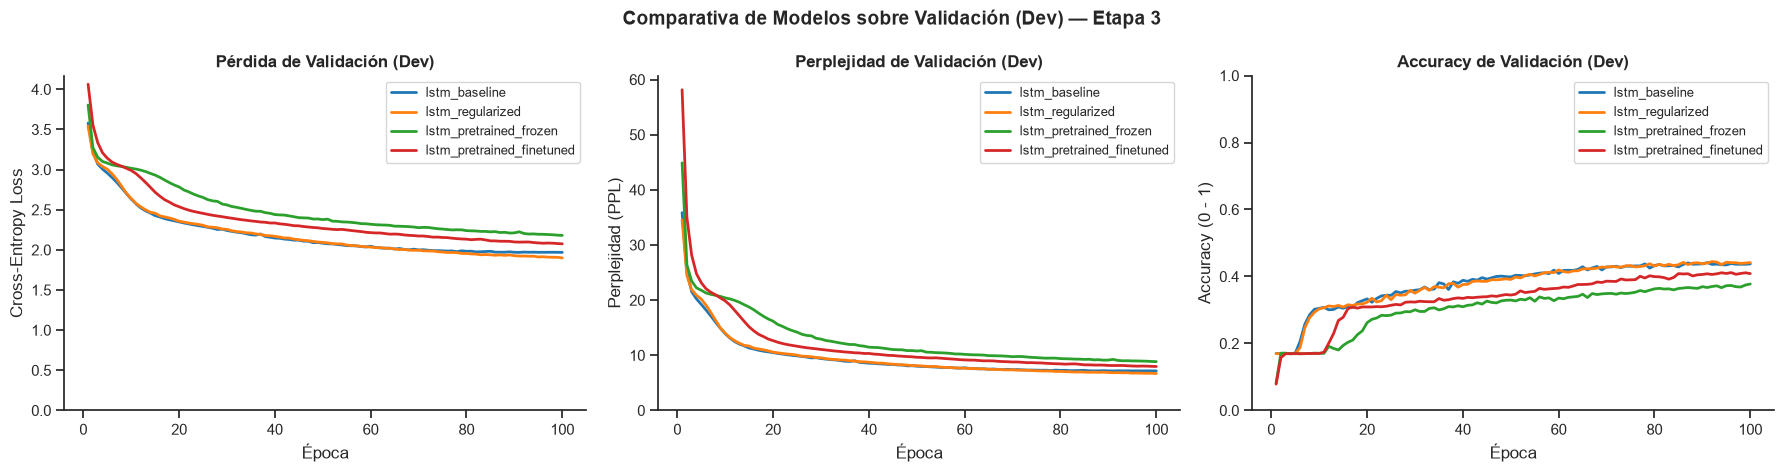

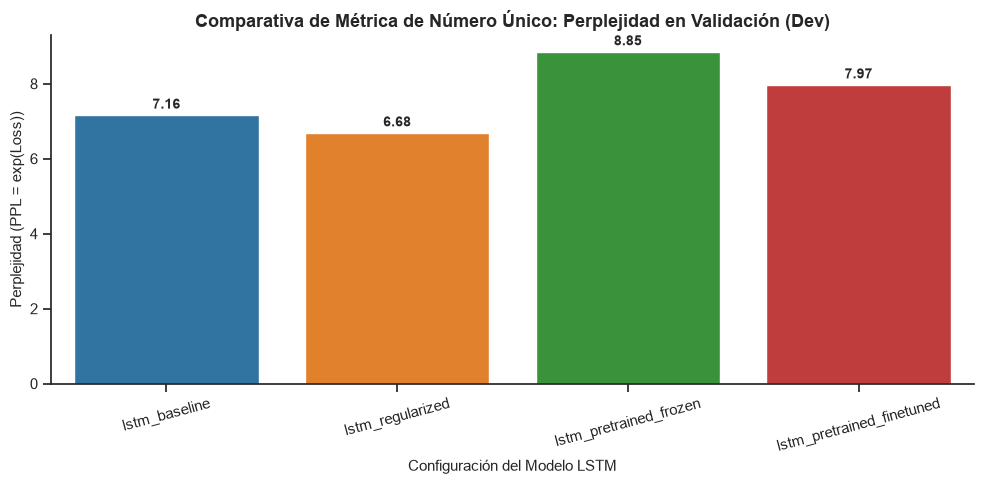


=== Evaluación Final en Test (lstm_regularized) ===
Test Loss:                2.0498
Test Perplejidad (Única): 7.77
Test BPC:                 2.957
Test Accuracy:            43.30%


In [6]:
# Tabla comparativa y gráficos
comparison_md = format_comparison_table(results_dict, stage2_reference=STAGE_2_REFERENCE)
plot_training_curves(results_dict)
plot_perplexity_comparison(results_dict, stage2_reference=STAGE_2_REFERENCE)

# Selección del mejor modelo según menor Perplejidad en Validación
best_model_key = min(results_dict, key=lambda k: results_dict[k]["best_val_perplexity"])
best_model = trained_models[best_model_key]

test_metrics: EvaluationResult = evaluate_model(
    model=best_model,
    dataset=ds_test,
    stage2_reference=STAGE_2_REFERENCE,
    verbose=0,
)

print(f"\n=== Evaluación Final en Test ({best_model_key}) ===")
print(f"Test Loss:                {test_metrics['loss']:.4f}")
print(f"Test Perplejidad (Única): {test_metrics['perplexity']:.2f}")
print(f"Test BPC:                 {test_metrics['bpc']:.3f}")
print(f"Test Accuracy:            {test_metrics['accuracy'] * 100:.2f}%")
if STAGE_2_REFERENCE["val_perplexity"] > 0:
    print(
        f"Mejora PPL vs Etapa 2:    {test_metrics['perplexity_reduction_abs']:+.2f} "
        f"({test_metrics['perplexity_reduction_pct']:+.2f}%)"
    )

---
## 6. Auditoría de Errores: Análisis de $\ge 10$ Ejemplos Difíciles

Extraemos los pasos temporales con mayor pérdida *Cross-Entropy* en `ds_test` para identificar qué patrones siguen resultando complejos para la LSTM (p. ej. inicio de palabras con alta entropía, vocabulario lovecraftiano, signos de puntuación o nombres propios).

In [7]:
hard_examples: list[HardExample] = extract_hard_examples(
    model=best_model,
    dataset=ds_test,
    tokenizer=tokenizer,
    num_examples=EVALUATION_CONFIG["hard_examples_count"],
    context_window=EVALUATION_CONFIG["hard_examples_context"],
)

hard_examples_md = format_hard_examples_table(hard_examples)

#### AUDITORÍA DE ERRORES — TOP 10 EJEMPLOS DIFÍCILES

,#,Categoría,Contexto Previo,Esperado,Predicho,P(Esp.),P(Pred.),Loss
0,1,Puntuación o salto de estructura,"'ard Low Latin.\n\n""The nethermost caverns,'","'""'",' ',0.0000,0.9445,13.6983
1,2,Puntuación o salto de estructura,"'thing about a ""psychosis,'","'""'",' ',0.0000,0.9382,13.2387
2,3,Morfología interna de palabra (vocabulario lit...,""" of Alhazred's ob""",'j','e',0.0000,0.4748,10.9475
3,4,Morfología interna de palabra (vocabulario lit...,'nd that is held by no head. Wisely did I','b',' ',0.0000,0.9527,10.5275
4,5,Inicio de oración o nombre propio (Mayúscula),'ex it and swell monstrous to plague it. ','G','T',0.0000,0.2737,10.0618
5,6,Morfología interna de palabra (vocabulario lit...,"'in, and\nhappy the town at night whose wi'",'z','n',0.0001,0.3536,9.8088
6,7,Puntuación o salto de estructura,'.\nThere was no one','—',' ',0.0001,0.8246,9.6505
7,8,Inicio de oración o nombre propio (Mayúscula),"""y sent me to St. Mary's """,'H','t',0.0001,0.1604,9.4728
8,9,Puntuación o salto de estructura,'.\nThere was no one—in waking hours','—',' ',0.0001,0.3728,9.3058
9,10,Inicio de oración o nombre propio (Mayúscula),"'ould say,\nbecause everything was wrong. '",'E','T',0.0001,0.3153,9.1595


---
## 7. Generación de Texto Literario (Muestreo con Temperatura) y Conclusiones

Evaluamos cualitativamente la capacidad generativa del mejor modelo usando distintas temperaturas ($T \in \{0.3, 0.7, 1.0, 1.1\}$):
- **$T$ baja ($0.3$):** Salidas conservadoras y ortográficamente estables, con riesgo de repetición.
- **$T$ intermedia ($0.7$):** Balance entre coherencia morfosintáctica y variedad estilística.
- **$T$ fiel ($1.0$):** Mantiene las probabilidades tal cual las devuelve el modelo, buscamos la mayor coherencia del texto.
- **$T$ alta ($1.1$):** Mayor creatividad léxica con mayor riesgo de neologismos (crear palabras que no existen) o errores.

In [8]:
seed_prompt = EVALUATION_CONFIG["generation_seed_text"]
num_chars = EVALUATION_CONFIG["generation_num_chars"]

for temp in EVALUATION_CONFIG["generation_temperatures"]:
    sample = generate_text(
        model=best_model,
        tokenizer=tokenizer,
        seed_text=seed_prompt,
        num_chars=num_chars,
        temperature=temp,
    )
    print(f"\n--- Temperatura T = {temp} ---")
    print(sample)


--- Temperatura T = 0.3 ---
The ancient town of Kingsport where the grown the prom of the street and and the sten and the streing the streally of the the the seart so the was the seart and the street and stone and the street and was the searting to the stri

--- Temperatura T = 0.7 ---
The ancient town of Kingsport of the hater its
and had fade to the farpear core and of state, and and stakned the row seen deor the know and was the consing bat stailly pure fullous had habless stran in the strest fest its inte p

--- Temperatura T = 1.0 ---
The ancient town of Kingsport antimed the high tha mid had flambeds
to veops thest and whene anoll Aaly
ond not leandly a d see broub the my canmonness. The was not the  was evere the ast
cinally pkes ope "fecisees were me thouge

--- Temperatura T = 1.1 ---
The ancient town of Kingsport gassigp chesting punchess coullowing pestrax. the it fide at may; I drow for a caming high the ever mate; I fad fold
the caples, ly matomed in the I galw glesing. T

---
### Conclusiones y Checklist de Etapa 3
- **Embeddings:** Se comparó el entrenamiento desde cero frente a inicialización pre-entrenada (`PPMI + SVD`) congelada y con ajuste fino.
- **Arquitectura:** Se implementó la capa `Embedding` dentro del modelo secuencial seguida de `LSTM` y cabezal denso (`Dense` + `Dropout` + `Logits`).